# 02 — Visualisation

**Entrée** : `data/processed/co2_clean.csv` (+ `data/external/world.geojson` pour les cartes)  
**Sortie** : figures enregistrées dans `reports/figures/`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

df = pd.read_csv('../data/processed/co2_clean.csv')
print(df.shape)
df.head()

(19787, 17)


,country,iso_code,year,population,gdp,co2,co2_per_capita,cumulative_co2,co2_growth_prct,coal_co2,oil_co2,gas_co2,land_use_change_co2,methane,nitrous_oxide,temperature_change_from_co2,temperature_change_from_ghg
0,Afghanistan,AFG,1949,7356890.0,NaN,0.014656,0.001992,0.014656,NaN,0.014656,0.000000,0.0,6.102172,7.729318,2.162319,0.000307,0.000528
1,Afghanistan,AFG,1950,7776180.0,9.421400e+09,0.084272,0.010837,0.098928,475.000000,0.021068,0.063204,0.0,7.084747,7.879157,2.230887,0.000311,0.000538
2,Afghanistan,AFG,1951,7879343.0,9.692280e+09,0.091600,0.011625,0.190528,8.695650,0.025648,0.065952,0.0,8.000418,7.972563,2.292099,0.000316,0.000548
3,Afghanistan,AFG,1952,7987784.0,1.001732e+10,0.091600,0.011468,0.282128,0.000000,0.031708,0.059892,0.0,8.913743,8.072992,2.365288,0.000321,0.000560
4,Afghanistan,AFG,1953,8096703.0,1.063052e+10,0.106256,0.013123,0.388384,15.999996,0.037949,0.068307,0.0,9.963808,8.185520,2.446641,0.000327,0.000571


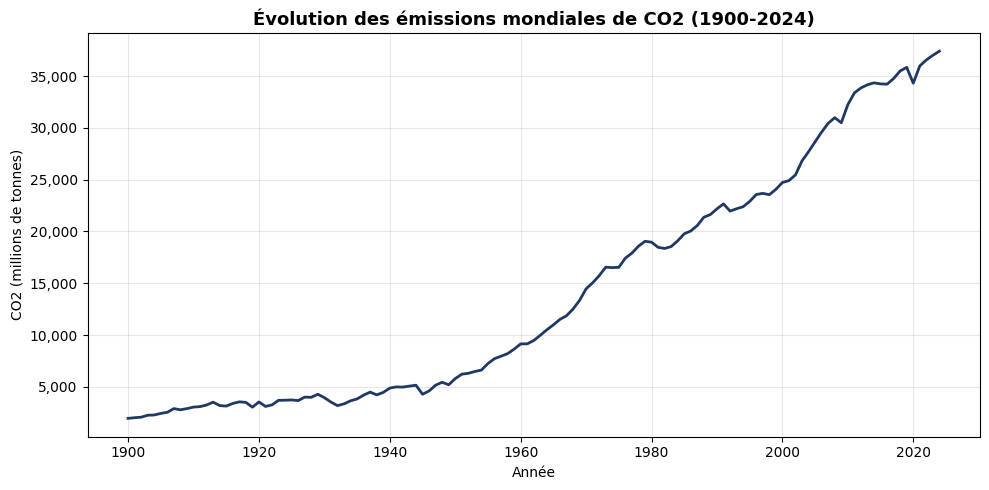

In [2]:
world_evolution = df.groupby('year')['co2'].sum()

fig, ax = plt.subplots()
ax.plot(world_evolution.index, world_evolution.values, color='#1F3864', linewidth=2)
ax.set_title("Évolution des émissions mondiales de CO2 (1900-2024)", fontsize=13, fontweight='bold')
ax.set_xlabel("Année")
ax.set_ylabel("CO2 (millions de tonnes)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.savefig('../reports/figures/fig_evolution_mondiale.png', dpi=120)
plt.show()

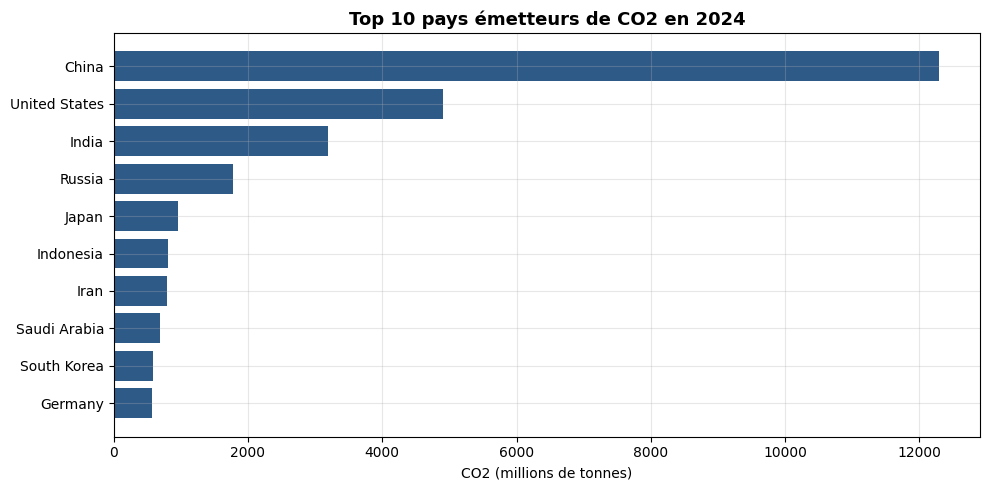

             country           co2
3793           China  12289.037109
18916  United States   4904.119629
8428           India   3193.478027
14737         Russia   1780.524414
9297           Japan    961.867310
8553       Indonesia    812.220215
8668            Iran    792.631165
15395   Saudi Arabia    692.133484
16532    South Korea    583.679138
7061         Germany    572.319153


In [3]:
last_year = df['year'].max()
top10_total = df[df['year'] == last_year].nlargest(10, 'co2')[['country', 'co2']]

fig, ax = plt.subplots()
ax.barh(top10_total['country'][::-1], top10_total['co2'][::-1], color='#2E5A88')
ax.set_title(f"Top 10 pays émetteurs de CO2 en {last_year}", fontsize=13, fontweight='bold')
ax.set_xlabel("CO2 (millions de tonnes)")
plt.tight_layout()
plt.savefig('../reports/figures/fig_top10_total.png', dpi=120)
plt.show()

print(top10_total)

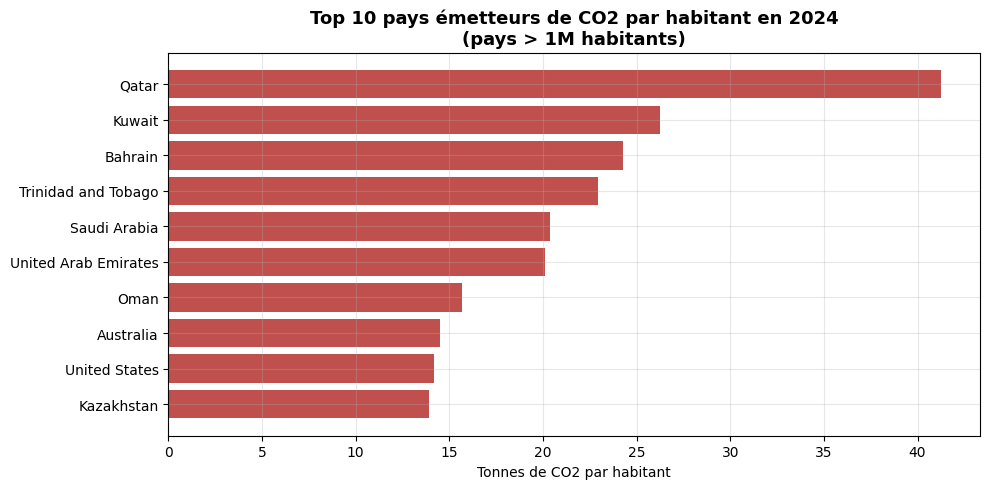

                    country  co2_per_capita
14487                 Qatar       41.271179
9715                 Kuwait       26.247530
1425                Bahrain       24.270082
17983   Trinidad and Tobago       22.931944
15395          Saudi Arabia       20.379194
18666  United Arab Emirates       20.131075
13416                  Oman       15.651107
1008              Australia       14.477199
18916         United States       14.197287
9497             Kazakhstan       13.937352


In [4]:
top10_capita = df[(df['year'] == last_year) & (df['population'] > 1_000_000)].nlargest(10, 'co2_per_capita')[['country', 'co2_per_capita']]

fig, ax = plt.subplots()
ax.barh(top10_capita['country'][::-1], top10_capita['co2_per_capita'][::-1], color='#C0504D')
ax.set_title(f"Top 10 pays émetteurs de CO2 par habitant en {last_year}\n(pays > 1M habitants)", fontsize=13, fontweight='bold')
ax.set_xlabel("Tonnes de CO2 par habitant")
plt.tight_layout()
plt.savefig('../reports/figures/fig_top10_capita.png', dpi=120)
plt.show()

print(top10_capita)

In [5]:
summary = df[df['year'] == last_year][['co2', 'co2_per_capita', 'gdp', 'population']].describe()
print(summary)

                co2  co2_per_capita  gdp    population
count    215.000000      213.000000  0.0  2.130000e+02
mean     173.944486        4.631773  NaN  3.827366e+07
std      937.302795        5.526467  NaN  1.445903e+08
min        0.000000        0.054032  NaN  1.841000e+03
25%        1.439799        1.013401  NaN  9.288000e+05
50%       10.825998        3.203721  NaN  7.186014e+06
75%       54.868938        6.018427  NaN  2.703242e+07
max    12289.037109       41.271179  NaN  1.450936e+09


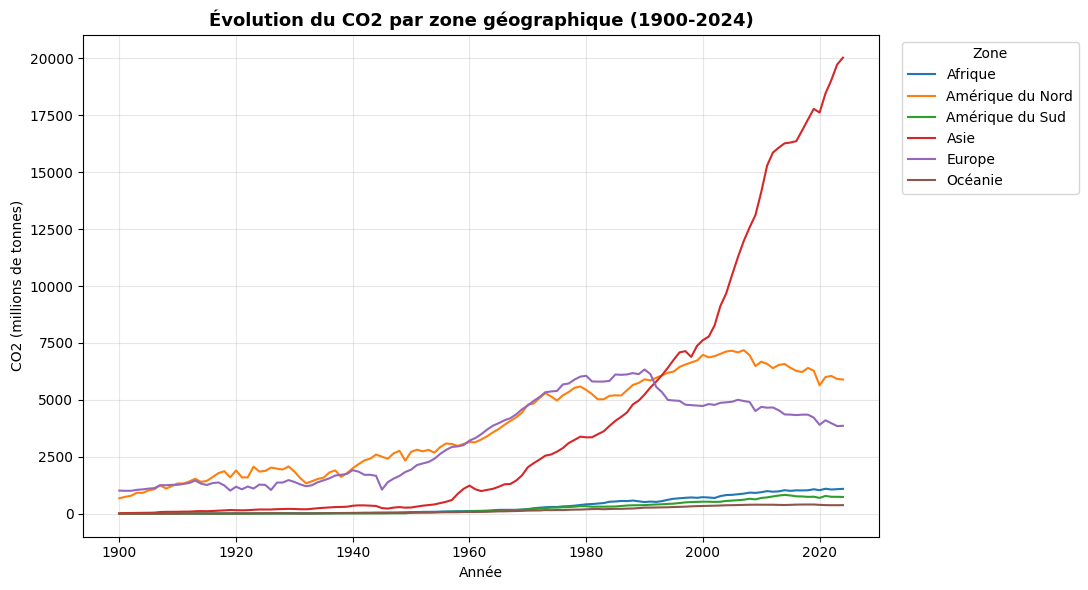

In [6]:
continent_map = {
    'China': 'Asie', 'India': 'Asie', 'Japan': 'Asie', 'Indonesia': 'Asie', 'Iran': 'Asie',
    'South Korea': 'Asie', 'Saudi Arabia': 'Asie', 'Turkey': 'Asie', 'Pakistan': 'Asie',
    'United States': 'Amérique du Nord', 'Canada': 'Amérique du Nord', 'Mexico': 'Amérique du Nord',
    'Brazil': 'Amérique du Sud', 'Argentina': 'Amérique du Sud', 'Colombia': 'Amérique du Sud',
    'Germany': 'Europe', 'Russia': 'Europe', 'United Kingdom': 'Europe', 'France': 'Europe',
    'Italy': 'Europe', 'Poland': 'Europe', 'Spain': 'Europe', 'Ukraine': 'Europe',
    'South Africa': 'Afrique', 'Egypt': 'Afrique', 'Nigeria': 'Afrique', 'Algeria': 'Afrique',
    'Morocco': 'Afrique', 'Australia': 'Océanie',
}

df['zone'] = df['country'].map(continent_map)
df_zone = df.dropna(subset=['zone'])

zone_evolution = df_zone.groupby(['year', 'zone'])['co2'].sum().unstack()

fig, ax = plt.subplots(figsize=(11, 6))
zone_evolution.plot(ax=ax)
ax.set_title("Évolution du CO2 par zone géographique (1900-2024)", fontsize=13, fontweight='bold')
ax.set_xlabel("Année")
ax.set_ylabel("CO2 (millions de tonnes)")
ax.legend(title="Zone", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../reports/figures/fig_zones.png', dpi=120)
plt.show()

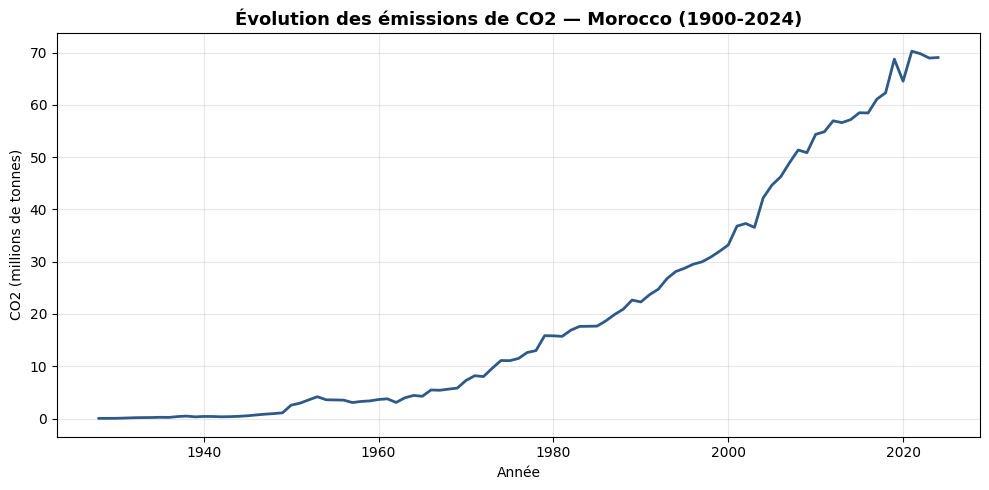

In [7]:
pays_choisi = 'Morocco'  # change le nom si tu veux un autre pays
df_pays = df[df['country'] == pays_choisi]

fig, ax = plt.subplots()
ax.plot(df_pays['year'], df_pays['co2'], color='#2E5A88', linewidth=2)
ax.set_title(f"Évolution des émissions de CO2 — {pays_choisi} (1900-2024)", fontsize=13, fontweight='bold')
ax.set_xlabel("Année")
ax.set_ylabel("CO2 (millions de tonnes)")
plt.tight_layout()
plt.savefig(f'../reports/figures/fig_{pays_choisi.lower()}.png', dpi=120)
plt.show()

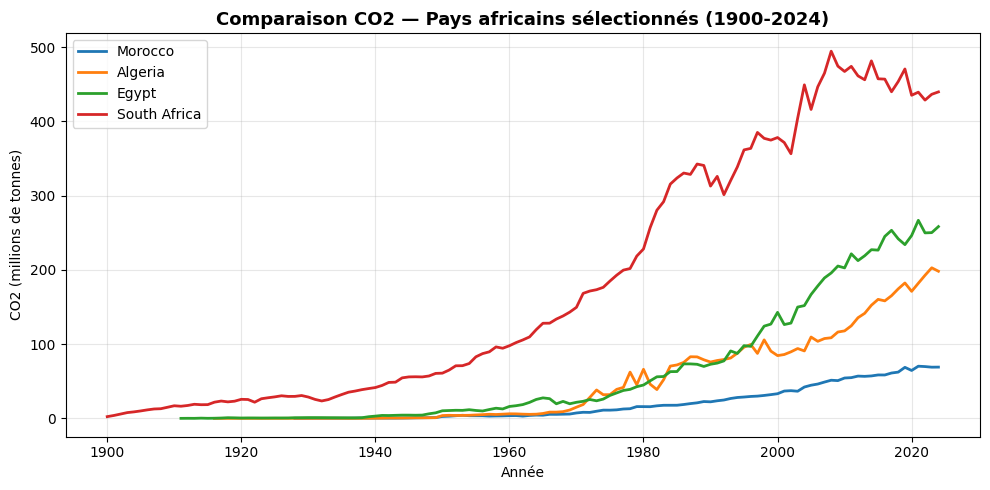

In [8]:
pays_liste = ['Morocco', 'Algeria', 'Egypt', 'South Africa']

fig, ax = plt.subplots()
for pays in pays_liste:
    sub = df[df['country'] == pays]
    ax.plot(sub['year'], sub['co2'], label=pays, linewidth=2)

ax.set_title("Comparaison CO2 — Pays africains sélectionnés (1900-2024)", fontsize=13, fontweight='bold')
ax.set_xlabel("Année")
ax.set_ylabel("CO2 (millions de tonnes)")
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/fig_comparaison_pays.png', dpi=120)
plt.show()

Pays avec données CO2 : 164 / 177


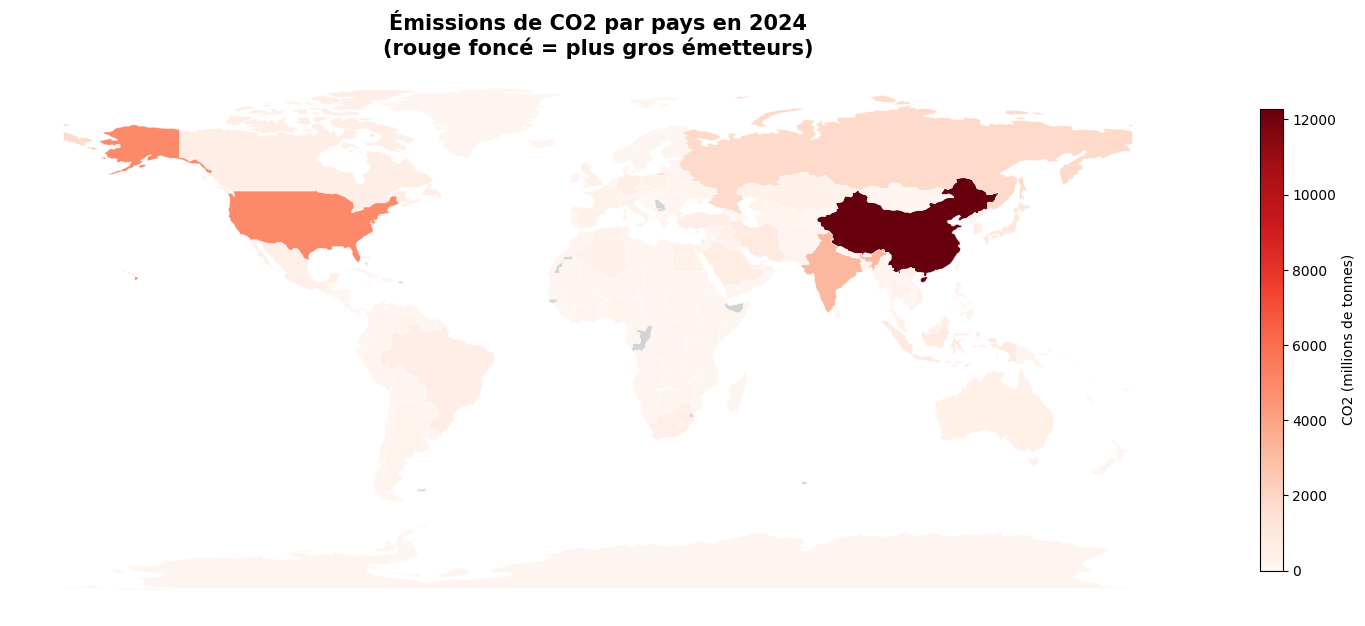

In [10]:
# Nécessite : pip install geopandas
# Nécessite le fichier ../data/external/world.geojson dans le même dossier (déjà fourni)
import geopandas as gpd

world = gpd.read_file('../data/external/world.geojson')
df_map = df[df['year'] == last_year].copy()

# Correction des noms de pays qui diffèrent entre les deux fichiers
rename_map = {
    'Congo': 'Republic of Congo',
    'Democratic Republic of Congo': 'Democratic Republic of the Congo',
    "Cote d'Ivoire": "Ivory Coast",
    'Czechia': 'Czech Republic',
    'North Macedonia': 'Macedonia',
    'Micronesia (country)': 'Federated States of Micronesia',
    'United States': 'United States of America',
    'Tanzania': 'United Republic of Tanzania',
}
df_map['country_geo'] = df_map['country'].replace(rename_map)

merged = world.merge(df_map, left_on='name', right_on='country_geo', how='left')
print("Pays avec données CO2 :", merged['co2'].notna().sum(), "/", len(merged))

fig, ax = plt.subplots(1, 1, figsize=(15, 8))
merged.plot(column='co2', ax=ax, legend=True, cmap='Reds',
            missing_kwds={'color': 'lightgrey', 'label': 'Pas de données'},
            edgecolor='white', linewidth=0.3,
            legend_kwds={'label': 'CO2 (millions de tonnes)', 'shrink': 0.6})
ax.set_title(f'Émissions de CO2 par pays en {int(last_year)}\n(rouge foncé = plus gros émetteurs)', fontsize=15, fontweight='bold')
ax.set_axis_off()
plt.tight_layout()
plt.savefig('../reports/figures/carte_co2.png', dpi=130, bbox_inches='tight')
plt.show()

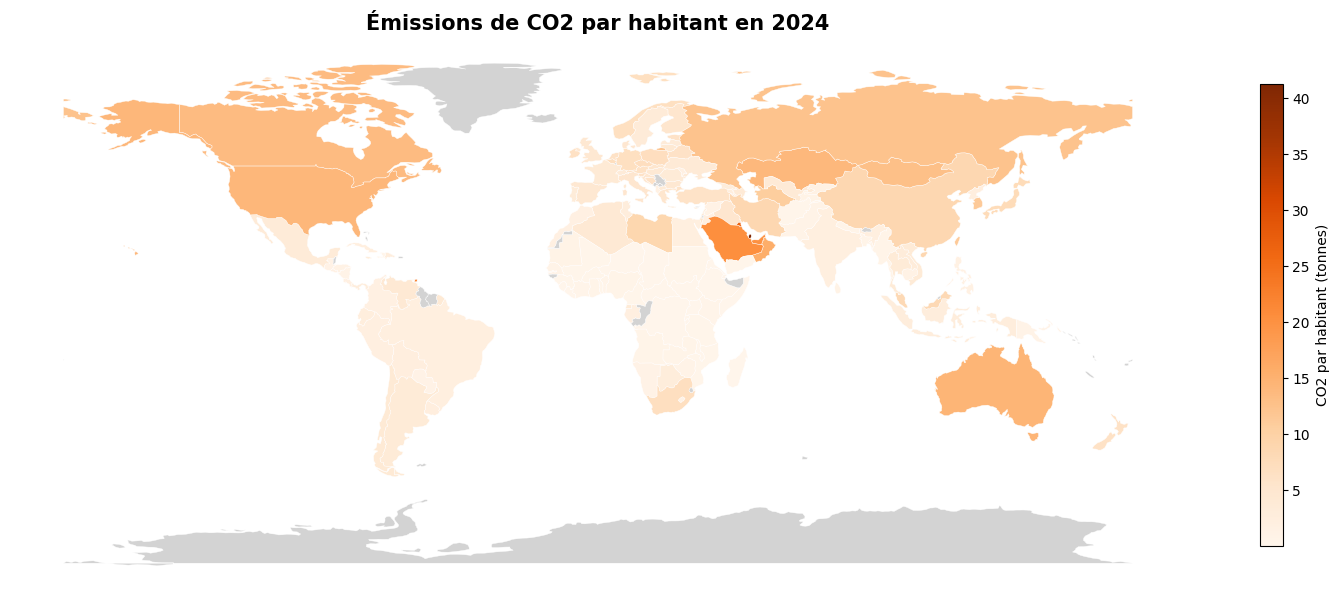

In [11]:
df_map2 = df_map[df_map['population'] > 1_000_000]
merged2 = world.merge(df_map2, left_on='name', right_on='country_geo', how='left')

fig, ax = plt.subplots(1, 1, figsize=(15, 8))
merged2.plot(column='co2_per_capita', ax=ax, legend=True, cmap='Oranges',
             missing_kwds={'color': 'lightgrey', 'label': 'Pas de données'},
             edgecolor='white', linewidth=0.3,
             legend_kwds={'label': 'CO2 par habitant (tonnes)', 'shrink': 0.6})
ax.set_title(f'Émissions de CO2 par habitant en {int(last_year)}', fontsize=15, fontweight='bold')
ax.set_axis_off()
plt.tight_layout()
plt.savefig('../reports/figures/carte_co2_par_habitant.png', dpi=130, bbox_inches='tight')
plt.show()